In [1]:
import sys
import os
import math

from matplotlib import pyplot as plt, colors, patches

import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), 'import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/worm-2025-fieseler/import/utils/train_utils.py'>

In [7]:
# read_ids = [0, 4, 5, 6, 27, 30, 31, 32, 33]
read_ids = list(range(0, 33 + 1))
plot_id = 19

dims = 2

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

In [8]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids, filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path, read_ids)

# for i in range(len(filenames)):
# 	mask = eigenworms[i].notna().all(axis=1)
# 	#continuous_behaviors[i] = continuous_behaviors[i][mask]
# 	discrete_states[i] = discrete_states[i][mask]
# 	eigenworms[i] = eigenworms[i][mask]
# 	traces[i] = traces[i][mask]
#
# 	#kymographs[i] = kymographs[i][mask]
# 	#filenames[i] = filenames[i][mask]

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

# manifold

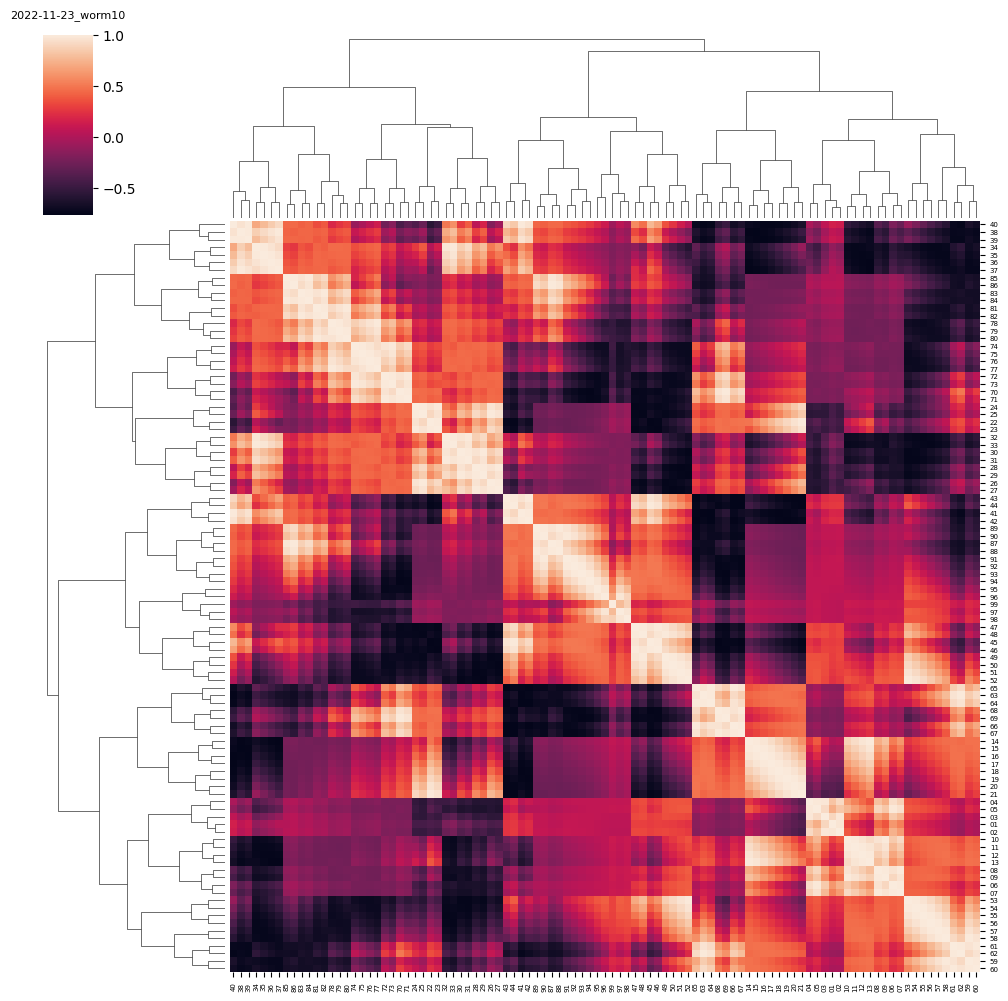

In [9]:
correlations = [trace.corr() for trace in traces]

# plot
heatmap = sns.clustermap(correlations[file_ids.index(plot_id)], yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(filenames[file_ids.index(plot_id)], fontsize=8, y=1.05)
plt.show()

In [6]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds(traces,
																[ds[selection_bhl] for ds in discrete_states],
																n_cc=dims, n_pc=5)

AttributeError: module 'utils.train_utils' has no attribute 'get_manifolds'

In [ ]:
# plot
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states], vars_expl_mans, vars_expl_mans_rs,
						  top_space=3)

In [ ]:
traces_manifolds_indices = [np.argsort(xloads_cca_man[:, 0]) for xloads_cca_man in loads_cca_man]
discrete_states_indices = [np.argsort(yloads_cca_man[:, 0])[::-1] for yloads_cca_man in loads_cca_man_b]

discrete_states_sorted = [ds[selection_bhl].iloc[:, ds_idx.tolist()] for ds, ds_idx in zip(discrete_states, discrete_states_indices)]
traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]

In [ ]:
# plot
plot_utils.plot_heatmap_stack(traces_sorted[file_ids.index(plot_id)], discrete_states_sorted[file_ids.index(plot_id)], 'neuronal traces', 'discrete states')

In [ ]:
# plot
plot_utils.plot_heatmap_stack(traces_manifolds_sorted[file_ids.index(plot_id)], discrete_states_sorted[file_ids.index(plot_id)], 'neuronal manifold traces', 'discrete states')

# concrete behavior

In [ ]:
traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]

traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]

In [ ]:
# plot
plot_utils.plot_heatmap_stack(traces_residuals_sorted_by_manifold[file_ids.index(plot_id)], discrete_states_sorted[file_ids.index(plot_id)], 'neuronal residual traces', 'discrete states')

In [ ]:
correlations_residuals = [trace_res.corr() for trace_res in traces_residuals]

# plot
heatmap = sns.clustermap(correlations_residuals[file_ids.index(plot_id)], xticklabels=True, yticklabels=True)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(filenames[file_ids.index(plot_id)], fontsize=8, y=1.05)
plt.show()

In [ ]:
n = eigenworms[file_ids.index(plot_id)].values.shape[1]

modes_concrete, modes_concrete_b = list(), list()
recos_concrete, recos_concrete_b = list(), list()
loads_cca_con, loads_cca_con_b = list(), list()
vars_expl_con, vars_expl_con_rs = list(), list()  # rs in this case: variance explained with respect to the manifold-residual data
for trace, trace_residual, ew in zip(traces, traces_residuals, eigenworms):
	cca = CCA(n_components=n, scale=True)

	trace_residual_reduced, ew_reduced = cca.fit_transform(trace_residual.values, ew.values)
	trace_residual_reconstructed, ew_reconstructed = cca.inverse_transform(trace_residual_reduced, ew_reduced)

	modes_concrete.append(pd.DataFrame(data=trace_residual_reduced, columns=[f'CC{i + 1}' for i in range(n)]))
	recos_concrete.append(pd.DataFrame(data=trace_residual_reconstructed, columns=trace_residual.columns))

	loads_cca_con.append(cca.x_loadings_)
	loads_cca_con_b.append(cca.y_loadings_)

	var_ratio = train_utils.get_variance_explained(trace_residual_reconstructed, trace)
	var_ratio_rs = train_utils.get_variance_explained(trace_residual_reconstructed, trace_residual)
	vars_expl_con.append(var_ratio)
	vars_expl_con_rs.append(var_ratio_rs)

In [ ]:
# plot
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids], modes_concrete, eigenworms, vars_expl_con, vars_expl_con_rs,
						  top_space=3)

In [ ]:
traces_concretes_indices = [np.argsort(xloads_cca_con[:, 0]) for xloads_cca_con in loads_cca_con]
eigenworms_indices = [np.argsort(yloads_cca_con[:, 0])[::-1] for yloads_cca_con in loads_cca_con_b]

eigenworms_sorted = [ew.iloc[:, ew_idx.tolist()] for ew, ew_idx in zip(eigenworms, eigenworms_indices)]
traces_concretes_sorted = [t_con.iloc[:, t_con_idx.tolist()] for t_con, t_con_idx in zip(recos_concrete, traces_concretes_indices)]

In [ ]:
traces_residuals_sorted_by_concretes = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_concretes_indices)]

# plot
plot_utils.plot_heatmap_stack(traces_residuals_sorted_by_concretes[file_ids.index(plot_id)], eigenworms_sorted[file_ids.index(plot_id)], 'neuronal residual traces', 'eigenworms')

In [ ]:
# plot
plot_utils.plot_heatmap_stack(traces_concretes_sorted[file_ids.index(plot_id)], eigenworms_sorted[file_ids.index(plot_id)], 'neuronal concrete traces', 'eigenworms')

In [ ]:
traces_concretes_sorted_by_manifold = [t_con.iloc[:, t_man_idx.tolist()] for t_con, t_man_idx in zip(recos_concrete, traces_manifolds_indices)]

# plot
plot_utils.plot_heatmap_stack(traces_concretes_sorted_by_manifold[file_ids.index(plot_id)], discrete_states_sorted[file_ids.index(plot_id)], 'neuronal concrete traces', 'discrete states')

# other

In [ ]:
traces_others = [pd.DataFrame(data=t_res.values - t_con.values, columns=t_res.columns) for t_res, t_con in zip(traces_residuals, recos_concrete)]

traces_others_sorted_by_concretes = [t_oth.iloc[:, t_con_idx.tolist()] for t_oth, t_con_idx in zip(traces_others, traces_concretes_indices)]

In [ ]:
# plot
plot_utils.plot_heatmap_stack(traces_others_sorted_by_concretes[file_ids.index(plot_id)], eigenworms_sorted[file_ids.index(plot_id)], 'neuronal other traces', 'eigenworms')

In [ ]:
traces_others_sorted_by_manifold = [t_oth.iloc[:, t_man_idx.tolist()] for t_oth, t_man_idx in zip(traces_others, traces_manifolds_indices)]

# plot
plot_utils.plot_heatmap_stack(traces_others_sorted_by_manifold[file_ids.index(plot_id)], discrete_states_sorted[file_ids.index(plot_id)], 'neuronal other traces', 'discrete states')

# total reconstruction error

In [ ]:
traces_diff = [pd.DataFrame(data=t.values - (t_man.values + t_con.values + t_oth.values), columns=t.columns) for t, t_man, t_con, t_oth in zip(traces, recos_manifold, recos_concrete, traces_others)]

plt.figure(figsize=(12, 6))

plt.imshow(traces_diff[file_ids.index(plot_id)].values.T, aspect='auto', cmap='rainbow', interpolation='nearest', norm=colors.Normalize(vmin=-0.3, vmax=0.8))
plt.ylabel("difference between original traces and m + c + o")
plt.yticks(np.arange(len(traces_diff[file_ids.index(plot_id)].values.T)), labels=traces_diff[file_ids.index(plot_id)].columns, fontsize=4)
plt.xticks(np.arange(0, len(traces_diff[file_ids.index(plot_id)].values), 100))
plt.colorbar(orientation='vertical', fraction=0.05)
plt.grid(False)

# variances per neuron per dataset

In [ ]:
mcos_full = list()
mco_ratios_full = list()
for i in range(len(filenames)):

	traces_all_var = np.var(traces[i].values, axis=0)
	traces_res_var = np.var(traces_residuals[i].values, axis=0)
	traces_man_var = traces_all_var - traces_res_var
	traces_oth_var = np.var(traces_others[i].values, axis=0)
	traces_con_var = traces_res_var - traces_oth_var
	mco = pd.DataFrame(data=np.vstack([traces_all_var, traces_man_var, traces_res_var, traces_con_var, traces_oth_var]),
					   columns=traces[i].columns,
					   index=['a', 'm', 'r', 'c', 'o'])
	mcos_full.append(mco)

	traces_all_var_ratio = traces_all_var / traces_all_var
	traces_res_var_ratio = traces_res_var / traces_all_var
	traces_man_var_ratio = traces_man_var / traces_all_var
	traces_oth_var_ratio = traces_oth_var / traces_all_var
	traces_con_var_ratio = traces_con_var / traces_all_var
	mco_ratio = pd.DataFrame(data=np.vstack([traces_all_var_ratio, traces_man_var_ratio, traces_res_var_ratio, traces_con_var_ratio, traces_oth_var_ratio]),
							 columns=traces[i].columns,
							 index=['a', 'm', 'r', 'c', 'o'])
	mco_ratios_full.append(mco_ratio)


neurons_labels = [traces[i].columns for i in range(len(filenames))]
unique_labels_full = sorted(list(set([l for label in neurons_labels for l in label])))
unique_labels = [label for label in unique_labels_full if label != '' and label[-1] != '_']

mcos = list()
for mco in mcos_full:
	mco_filtered = mco[sorted(list(set(unique_labels) & set(mco.columns)))]
	if len(mco_filtered.columns) > 0:
		mcos.append(mco_filtered)
mco_ratios = list()
for mco_ratio in mco_ratios_full:
	mco_ratio_filtered = mco_ratio[sorted(list(set(unique_labels) & set(mco_ratio.columns)))]
	if len(mco_ratio_filtered.columns) > 0:
		mco_ratios.append(mco_ratio_filtered)

# variances per neuron averaged over datasets

In [ ]:
mcos_avg = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
mcos_std = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
for neuron in unique_labels:
	amrco = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco in mcos:
		if neuron in mco.columns:
			for key in amrco.keys():
				amrco[key].append(mco[neuron][key])
	mcos_avg[neuron] = [np.mean(np.array(amrco[key])) for key in amrco.keys()]
	mcos_std[neuron] = [np.std(np.array(amrco[key])) for key in amrco.keys()]

In [ ]:
mco_ratios_avg = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
mco_ratios_std = pd.DataFrame(index=['a', 'm', 'r', 'c', 'o'], columns=unique_labels)
for neuron in unique_labels:
	amrco_ratio = {'a': [], 'm': [], 'r': [], 'c': [], 'o': []}
	for mco_ratio in mco_ratios:
		if neuron in mco_ratio.columns:
			for key in amrco_ratio.keys():
				amrco_ratio[key].append(mco_ratio[neuron][key])
	mco_ratios_avg[neuron] = [np.mean(np.array(amrco_ratio[key])) for key in amrco_ratio.keys()]
	mco_ratios_std[neuron] = [np.std(np.array(amrco_ratio[key])) for key in amrco_ratio.keys()]

# M-C-O ratio bar plots

In [ ]:
mco_ratio_c_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='c', ascending=False).T
mco_ratio_c_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_c_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_c_avg, mco_ratio_c_std, mco_ratio_c_avg.columns, ['c', 'm', 'o'])

In [ ]:
mco_ratio_m_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='m', ascending=False).T
mco_ratio_m_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_m_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_m_avg, mco_ratio_m_std, mco_ratio_m_avg.columns, ['m', 'c', 'o'])

In [ ]:
mco_ratio_o_avg = mco_ratios_avg.T[['m', 'c', 'o']].sort_values(by='o', ascending=False).T
mco_ratio_o_std = mco_ratios_std.T[['m', 'c', 'o']].reindex(mco_ratio_o_avg.T.index).T

# plot
plot_utils.plot_mcos(mco_ratio_o_avg, mco_ratio_o_std, mco_ratio_o_avg.columns, ['m', 'c', 'o'])

# M-C-O bar plots

In [ ]:
mco_m_avg = mcos_avg.T.sort_values(by='a', ascending=False)[['m', 'c', 'o']].T
mco_m_std = mcos_std.T.reindex(mco_m_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_m_avg, mco_m_std, mco_m_avg.columns, ['m', 'c', 'o'],
					 normalized=False)

In [ ]:
mco_m_avg = mcos_avg.T.sort_values(by='m', ascending=False)[['m', 'c', 'o']].T
mco_m_std = mcos_std.T.reindex(mco_m_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_m_avg, mco_m_std, mco_m_avg.columns, ['m', 'c', 'o'],
					 normalized=False)

In [ ]:
mco_c_avg = mcos_avg.T.sort_values(by='c', ascending=False)[['m', 'c', 'o']].T
mco_c_std = mcos_std.T.reindex(mco_c_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_c_avg, mco_c_std, mco_c_avg.columns, ['c', 'm', 'o'],
					 normalized=False)

In [ ]:
mco_o_avg = mcos_avg.T.sort_values(by='o', ascending=False)[['m', 'c', 'o']].T
mco_o_std = mcos_std.T.reindex(mco_o_avg.T.index)[['m', 'c', 'o']].T

# plot
plot_utils.plot_mcos(mco_o_avg, mco_o_std, mco_o_avg.columns, ['o', 'c', 'm'],
					 normalized=False)